In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import numpy.typing as npt
import random 
import matplotlib.pyplot as plt
import pandas as pd
import time
import math

import tensorflow as tf
from keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import SGD  # Stochastic Gradient Descent
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import sqrt
from keras.optimizers import *

2024-04-12 13:56:53.813008: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-12 13:56:53.946877: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/kaan/summer_ws/devel/lib:/home/kaan/rob_ws/devel/lib:/home/kaan/aria_ws/devel/lib:/home/kaan/catkin_ws/devel/lib:/opt/ros/noetic/lib:/opt/ros/noetic/lib/x86_64-linux-gnu:/home/kaan/.local/lib/python3.9/site-packages/nvidia/cudnn/lib:/usr/local/cuda-12/lib64
2024-04-12 13:56:53.946896: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do n

In [2]:
df = pd.read_csv('gazebo_full_dataset_synced.csv')

In [3]:
df

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,76.109,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,76.110,0.479692,-0.115205,0.905620,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...,...,...,...,...
65571,336.884,0.120041,0.831571,0.316904,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65572,336.884,0.120041,0.831571,0.316904,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65573,336.884,0.120041,0.831571,0.316904,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65574,336.944,0.120041,0.831571,0.316904,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660


In [4]:
df.describe()

,Time,x,y,z,theta0,theta1,theta2,theta3,theta4,theta5,theta6
count,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000,65576.000000
mean,1652.213097,0.051802,0.045639,0.765062,0.217698,0.099319,-0.111246,0.909160,-0.313598,-1.919095,-0.092457
std,2670.698643,0.337106,0.373114,0.370713,1.411671,0.913964,2.235877,4.244100,1.471447,9.313334,1.931103
min,76.109000,-0.794150,-0.840471,-0.716202,-2.678119,-1.870202,-8.088039,-2.036752,-2.940508,-43.638002,-16.426336
25%,161.900000,-0.155679,-0.203097,0.470713,-0.582789,-0.465490,-0.820537,-0.750861,-1.624486,-0.767569,-1.324234
50%,243.990000,0.009356,-0.000005,0.814652,0.017203,0.000031,0.000248,0.000057,0.000005,-0.000016,-0.000072
75%,325.504000,0.287963,0.309884,1.104910,1.140992,0.775909,1.366388,0.958525,0.622370,0.815995,1.392445
max,6658.649000,1.000957,0.831571,1.220999,2.867152,1.904753,2.846485,19.466906,2.922250,2.400718,2.957545


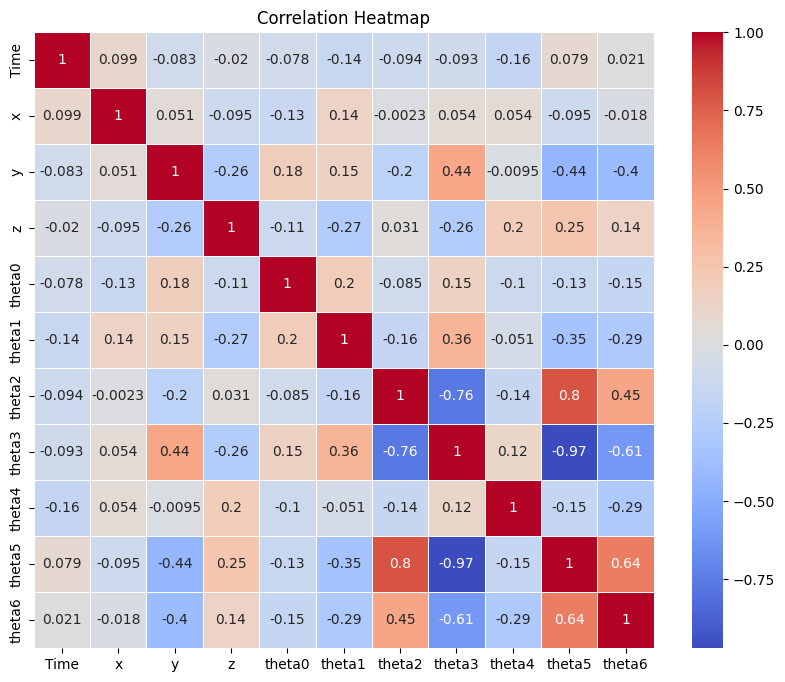

In [5]:
#Plotting correlation heatmap
correlation_matrix =df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5) 
plt.title("Correlation Heatmap")
plt.show()

In [6]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
65571,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65572,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65573,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660
65574,1.140991,1.502189,-8.088039,19.466906,0.608820,-43.515041,-5.619660


In [7]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
65571,0.120041,0.831571,0.316904
65572,0.120041,0.831571,0.316904
65573,0.120041,0.831571,0.316904
65574,0.120041,0.831571,0.316904


In [8]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_s = x_scaler.fit_transform(X)
y_s = y_scaler.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size = 0.2, random_state=42)

In [9]:
X.shape

(65576, 3)

### relu activation

In [10]:
model = Sequential([
    Dense(300, activation='tanh', input_shape=(X_train.shape[1],)),
    Dense(300, activation='tanh'),
    Dense(128, activation='tanh'),
    Dense(32, activation='tanh'),
    Dense(y_train.shape[1], activation='linear')  # Adjust the number of units to match your output shape
])

model.compile(optimizer=SGD(learning_rate=0.017, momentum=0.9), loss='mean_squared_error', metrics=['mse'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 300)               1200      
                                                                 
 dense_1 (Dense)             (None, 300)               90300     
                                                                 
 dense_2 (Dense)             (None, 128)               38528     
                                                                 
 dense_3 (Dense)             (None, 32)                4128      
                                                                 
 dense_4 (Dense)             (None, 7)                 231       
                                                                 
Total params: 134,387
Trainable params: 134,387
Non-trainable params: 0
_________________________________________________________________


2024-04-12 13:58:06.962013: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-04-12 13:58:06.962382: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/kaan/summer_ws/devel/lib:/home/kaan/rob_ws/devel/lib:/home/kaan/aria_ws/devel/lib:/home/kaan/catkin_ws/devel/lib:/opt/ros/noetic/lib:/opt/ros/noetic/lib/x86_64-linux-gnu:/home/kaan/.local/lib/python3.9/site-packages/nvidia/cudnn/lib:/usr/local/cuda-12/lib64
2024-04-12 13:58:06.962523: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory; LD

In [11]:
history = model.fit(X_train, y_train, epochs=250, batch_size=64, validation_split=0.2, verbose=1)


Epoch 1/250
656/656 [==============================] - 2s 3ms/step - loss: 0.5504 - mse: 0.5504 - val_loss: 0.4174 - val_mse: 0.4174
Epoch 2/250
656/656 [==============================] - 2s 3ms/step - loss: 0.3624 - mse: 0.3624 - val_loss: 0.3217 - val_mse: 0.3217
Epoch 3/250
656/656 [==============================] - 2s 3ms/step - loss: 0.2902 - mse: 0.2902 - val_loss: 0.2678 - val_mse: 0.2678
Epoch 4/250
656/656 [==============================] - 3s 4ms/step - loss: 0.2512 - mse: 0.2512 - val_loss: 0.2332 - val_mse: 0.2332
Epoch 5/250
656/656 [==============================] - 3s 4ms/step - loss: 0.2223 - mse: 0.2223 - val_loss: 0.2114 - val_mse: 0.2114
Epoch 6/250
656/656 [==============================] - 2s 3ms/step - loss: 0.1982 - mse: 0.1982 - val_loss: 0.1860 - val_mse: 0.1860
Epoch 7/250
656/656 [==============================] - 2s 3ms/step - loss: 0.1827 - mse: 0.1827 - val_loss: 0.1698 - val_mse: 0.1698
Epoch 8/250
656/656 [==============================] - 2s 3ms/step - 

656/656 [==============================] - 2s 4ms/step - loss: 0.0211 - mse: 0.0211 - val_loss: 0.0229 - val_mse: 0.0229
Epoch 124/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0208 - mse: 0.0208 - val_loss: 0.0228 - val_mse: 0.0228
Epoch 125/250
656/656 [==============================] - 2s 4ms/step - loss: 0.0206 - mse: 0.0206 - val_loss: 0.0235 - val_mse: 0.0235
Epoch 126/250
656/656 [==============================] - 3s 4ms/step - loss: 0.0205 - mse: 0.0205 - val_loss: 0.0242 - val_mse: 0.0242
Epoch 127/250
656/656 [==============================] - 3s 4ms/step - loss: 0.0205 - mse: 0.0205 - val_loss: 0.0221 - val_mse: 0.0221
Epoch 128/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0201 - mse: 0.0201 - val_loss: 0.0224 - val_mse: 0.0224
Epoch 129/250
656/656 [==============================] - 2s 4ms/step - loss: 0.0200 - mse: 0.0200 - val_loss: 0.0217 - val_mse: 0.0217
Epoch 130/250
656/656 [==============================] - 2s 3ms/step 

Epoch 184/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0152 - mse: 0.0152 - val_loss: 0.0175 - val_mse: 0.0175
Epoch 185/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0154 - mse: 0.0154 - val_loss: 0.0170 - val_mse: 0.0170
Epoch 186/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0153 - mse: 0.0153 - val_loss: 0.0173 - val_mse: 0.0173
Epoch 187/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0150 - mse: 0.0150 - val_loss: 0.0171 - val_mse: 0.0171
Epoch 188/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0150 - mse: 0.0150 - val_loss: 0.0182 - val_mse: 0.0182
Epoch 189/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0149 - mse: 0.0149 - val_loss: 0.0177 - val_mse: 0.0177
Epoch 190/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0149 - mse: 0.0149 - val_loss: 0.0174 - val_mse: 0.0174
Epoch 191/250
656/656 [==============================] 

### tanh activation

In [13]:
modelt = Sequential([
    Dense(300, activation='tanh', input_shape=(X_train.shape[1],)),
    Dense(300, activation='tanh'),
    Dense(128, activation='tanh'),
    Dense(32, activation='tanh'),
    Dense(y_train.shape[1], activation='linear')  # Adjust the number of units to match your output shape
])

modelt.compile(optimizer=SGD(learning_rate=0.015, momentum=0.9), loss='mean_squared_error', metrics=['mse'])
modelt.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 300)               1200      
                                                                 
 dense_6 (Dense)             (None, 300)               90300     
                                                                 
 dense_7 (Dense)             (None, 128)               38528     
                                                                 
 dense_8 (Dense)             (None, 32)                4128      
                                                                 
 dense_9 (Dense)             (None, 7)                 231       
                                                                 
Total params: 134,387
Trainable params: 134,387
Non-trainable params: 0
_________________________________________________________________


In [14]:
historyt = modelt.fit(X_train, y_train, epochs=250, batch_size=64, validation_split=0.2, verbose=1)

Epoch 1/250
656/656 [==============================] - 2s 3ms/step - loss: 0.5651 - mse: 0.5651 - val_loss: 0.4040 - val_mse: 0.4040
Epoch 2/250
656/656 [==============================] - 2s 3ms/step - loss: 0.3567 - mse: 0.3567 - val_loss: 0.3152 - val_mse: 0.3152
Epoch 3/250
656/656 [==============================] - 2s 3ms/step - loss: 0.2936 - mse: 0.2936 - val_loss: 0.2744 - val_mse: 0.2744
Epoch 4/250
656/656 [==============================] - 2s 3ms/step - loss: 0.2590 - mse: 0.2590 - val_loss: 0.2438 - val_mse: 0.2438
Epoch 5/250
656/656 [==============================] - 2s 3ms/step - loss: 0.2332 - mse: 0.2332 - val_loss: 0.2216 - val_mse: 0.2216
Epoch 6/250
656/656 [==============================] - 2s 3ms/step - loss: 0.2129 - mse: 0.2129 - val_loss: 0.2121 - val_mse: 0.2121
Epoch 7/250
656/656 [==============================] - 2s 3ms/step - loss: 0.1964 - mse: 0.1964 - val_loss: 0.1877 - val_mse: 0.1877
Epoch 8/250
656/656 [==============================] - 2s 3ms/step - 

656/656 [==============================] - 2s 3ms/step - loss: 0.0220 - mse: 0.0220 - val_loss: 0.0240 - val_mse: 0.0240
Epoch 124/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0218 - mse: 0.0218 - val_loss: 0.0249 - val_mse: 0.0249
Epoch 125/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0218 - mse: 0.0218 - val_loss: 0.0235 - val_mse: 0.0235
Epoch 126/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0216 - mse: 0.0216 - val_loss: 0.0232 - val_mse: 0.0232
Epoch 127/250
656/656 [==============================] - 2s 4ms/step - loss: 0.0215 - mse: 0.0215 - val_loss: 0.0242 - val_mse: 0.0242
Epoch 128/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0214 - mse: 0.0214 - val_loss: 0.0230 - val_mse: 0.0230
Epoch 129/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0211 - mse: 0.0211 - val_loss: 0.0226 - val_mse: 0.0226
Epoch 130/250
656/656 [==============================] - 2s 3ms/step 

Epoch 184/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0161 - mse: 0.0161 - val_loss: 0.0182 - val_mse: 0.0182
Epoch 185/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0161 - mse: 0.0161 - val_loss: 0.0183 - val_mse: 0.0183
Epoch 186/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0160 - mse: 0.0160 - val_loss: 0.0176 - val_mse: 0.0176
Epoch 187/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0157 - mse: 0.0157 - val_loss: 0.0178 - val_mse: 0.0178
Epoch 188/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0158 - mse: 0.0158 - val_loss: 0.0174 - val_mse: 0.0174
Epoch 189/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0156 - mse: 0.0156 - val_loss: 0.0175 - val_mse: 0.0175
Epoch 190/250
656/656 [==============================] - 2s 3ms/step - loss: 0.0156 - mse: 0.0156 - val_loss: 0.0174 - val_mse: 0.0174
Epoch 191/250
656/656 [==============================] 

-
-
-
-

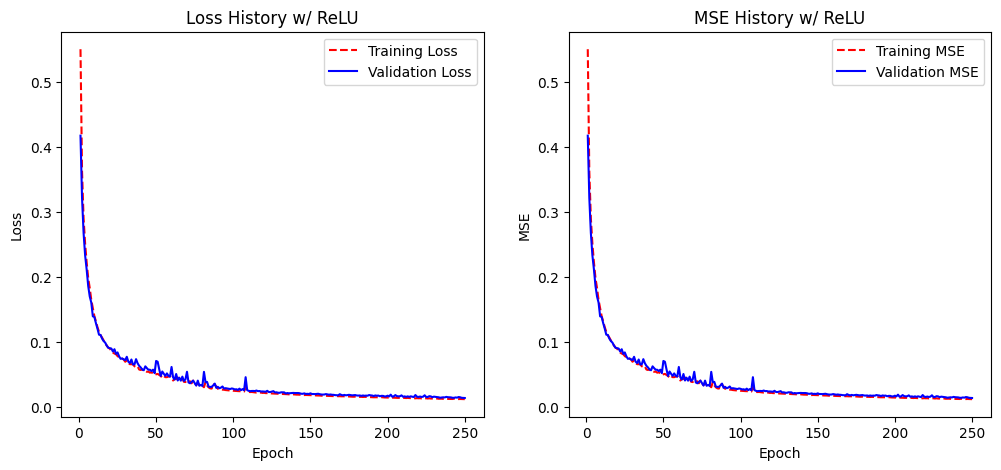

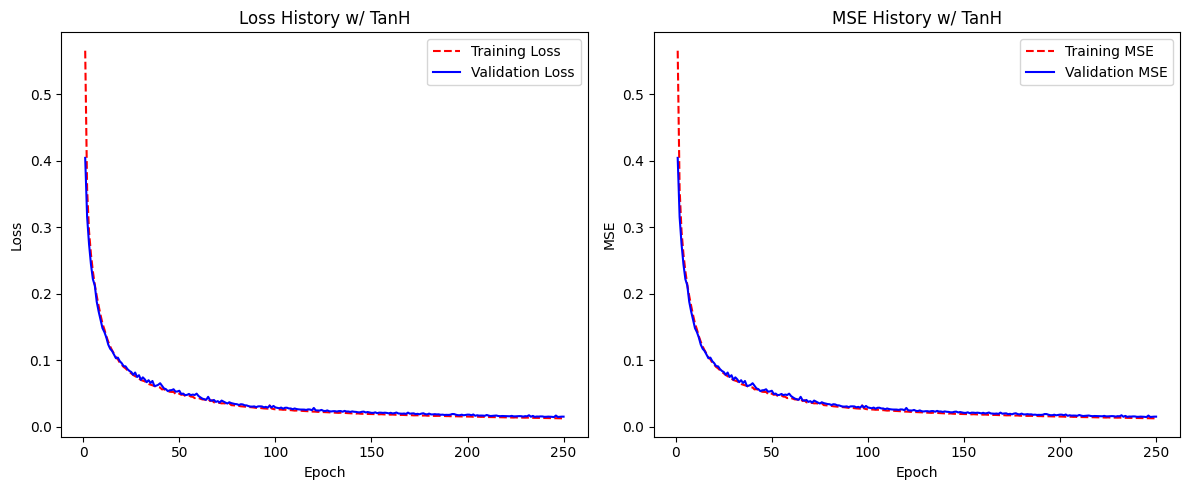

In [16]:
#test_loss = model.evaluate(X_test, y_test, verbose=0)
#print(f'Test loss: {test_loss}')

# Get training and validation loss histories
training_loss = history.history['loss']
validation_loss = history.history['val_loss']  # Corrected to 'val_loss'

# Get training and validation MSE (Mean Squared Error) histories
# Assuming you've used 'mse' as a metric during model compilation
training_mse = history.history['mse']
validation_mse = history.history['val_mse']  # Corrected to 'val_mse'

# Get training and validation loss histories
training_losst = historyt.history['loss']
validation_losst = historyt.history['val_loss']  # Corrected to 'val_loss'

# Get training and validation MSE (Mean Squared Error) histories
# Assuming you've used 'mse' as a metric during model compilation
training_mset = historyt.history['mse']
validation_mset = historyt.history['val_mse']  # Corrected to 'val_mse'

# Create count of the number of epochs
epoch_count = range(1, len(training_losst) + 1)


# Visualize loss history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epoch_count, training_loss, 'r--')
plt.plot(epoch_count, validation_loss, 'b-')
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss History w/ ReLU')

plt.subplot(1, 2, 2)
plt.plot(epoch_count, training_mse, 'r--')
plt.plot(epoch_count, validation_mse, 'b-')
plt.legend(['Training MSE', 'Validation MSE'])
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('MSE History w/ ReLU')

###################
# Visualize loss history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epoch_count, training_losst, 'r--')
plt.plot(epoch_count, validation_losst, 'b-')
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss History w/ TanH')

plt.subplot(1, 2, 2)
plt.plot(epoch_count, training_mset, 'r--')
plt.plot(epoch_count, validation_mset, 'b-')
plt.legend(['Training MSE', 'Validation MSE'])
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('MSE History w/ TanH')
#####################

plt.tight_layout()
plt.show()

-
-
-

In [20]:
y_pred = model.predict(X_test)

y_pred = pd.DataFrame(y_scaler.inverse_transform(y_pred))
y_test = pd.DataFrame(y_scaler.inverse_transform(y_test))

result_mse = []
result_mae = []

for i in range(7):

    mse = mean_squared_error(y_test.iloc[:,i], y_pred.iloc[:,i])
    rmse = sqrt(mse) 
    mae = mean_absolute_error(y_test.iloc[:,i], y_pred.iloc[:,i])
    result_mse.append(mse)
    result_mae.append(mae)

print("RMSE:\n", result_mse)
print("\n\nMAE:\n", result_mae)

410/410 [==============================] - 1s 1ms/step
RMSE:
 [2.609834499344709, 0.06622613224457043, 80.68864342525521, 5616.108963997399, 4.431985415990193, 670004.9870043496, 28.38530904353109]


MAE:
 [1.3190744598105184, 0.2181813773761086, 5.842810409741374, 30.196000076486577, 1.6622948119641643, 247.3173891203048, 4.010531687748765]


In [24]:
# Example prediction
new_sequence = np.array([[-0.3,-0.3,0.6]])  # New test positions here
predicted_angles = model.predict(new_sequence)
print(predicted_angles)


1/1 [==============================] - 0s 22ms/step
[[ 0.7603519   0.5974973  -0.1538074   0.09256303  0.58375335  0.2642727
   0.60425544]]


-
-
-